## Pediatric AML Model

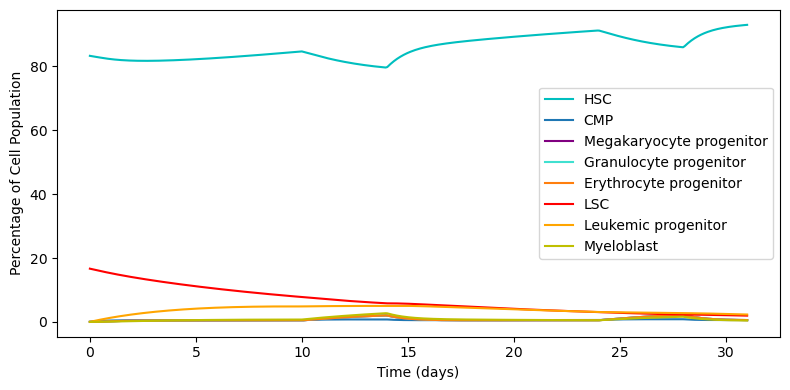

In [23]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# General Parameters
H0 = 100000 # healthy HSCs
CM0 = 0 # CMPs
K0 = 0 # megakaryocyte progenitors
G0 = 0 # granulocyte progenitors
E0 = 0 # erythrocyte progenitors
L0 = 20000 # LSCs
LP0 = 0 # leukemic progenitors
B0 = 0 # myeloblasts
D0 = 0 # dead cells

y0 = [H0, CM0, K0, G0, E0, L0, LP0, B0, D0]
t_span = (0, 31)
t_eval = np.linspace(*t_span, 401)

# Rates
aH = 0.85 # renewal rate of HSCs
aCM = 0.7 # renewal rate of CMPs
aL = 0.25 # renewal rate of LSCs
aLP = 0.15 # renewal rate of leukemic progenitors
pH = 0.04 # proliferation rate of HSCs
pCM = 0.7644 # proliferation rate of CMPs
pK = 1 # proliferation rate of megakaryocyte progenitors 
pG = 1 # proliferation rate of  granulocyte progenitors 
pE = 1 # prolfieration rate of erythrocyte prongenitors
pL = 0.06 # proliferation rate of LSCs
pLP = 0.1 # proliferation rate of leukemic progenitors
pB = 1 # proliferation rate of myeloblasts 
dB = 0.145 # death rate of myeloblasts
dP = 0.3 # death rate of healthy immature progenitors
dC = 0.99 # kill rate of chemo
EQ = 1.6 * 10**-10 # equilibrium constant
KB = 1/3 # differentiation bias from CMP to megakaryocyte progenitor
GB = 1/3 # differentiation bias from CMP to granulocyte progenitor
EB = 1/3 # differentiation bias from CMP to erythrocyte progenitor

#Treatment period. 5 days on treatment every week.  
def chemo(t, period=14, duration=10, start=0):
    t_shift = (t - start) % period
    return 1.0 if t_shift < duration else 0.

def leuk_model(t, y, aH, aCM, aL, aLP, pH, pCM, pL, pLP, dB, dP, dC, EQ, KB, GB, EB):
    H, CM, K, G, E, L, LP, B, D = y
    dHdt = (2 * aH * 1/(1 + EQ * CM + EQ * B) - 1) * pH * H - (chemo(t) * dC * pH * H)
    dCMdt = 2 * (1 - aH * 1/(1 + EQ * CM + EQ * B)) * pH * H + (2 * aCM * KB * 1/(1 + EQ * G + EQ * B) - 1) * pCM * CM + (2 * aCM * GB * 1/(1 + EQ * G + EQ * B) - 1) * pCM * CM + (2 * aCM * EB * 1/(1 + EQ * G + EQ * B) - 1) * pCM * CM - (chemo(t) * dC * pCM * CM)
    dKdt = 2 * (1 - aCM * KB * 1/(1 + EQ * CM + EQ * B)) * pCM * CM - dP * K - (chemo(t) * dC * pK * K)
    dGdt = 2 * (1 - aCM * GB * 1/(1 + EQ * CM + EQ * B)) * pCM * CM - dP * G - (chemo(t) * dC * pG * G)
    dEdt = 2 * (1 - aCM * EB * 1/(1 + EQ * CM + EQ * B)) * pCM * CM - dP * E - (chemo(t) * dC * pE * E)
    dLdt = (2 * aL * 1/(1 + EQ * CM + EQ * B) - 1) * pL * L - (chemo(t) * dC * pL * L)
    dLPdt = 2 * (1 - aL * 1/(1 + EQ * CM + EQ * B)) * pL * L + (2 * aLP * 1/(1 + EQ * CM + EQ * B) - 1) * pLP * LP - (chemo(t) * dC * pLP * LP)
    dBdt = 2 * (1 - aLP * 1/(1 + EQ * CM + EQ * B)) * pLP * LP - dB * B - (chemo(t) * dC * pB * B)
    dDdt = dP * K + dP * G + dP * E + dB * B + (chemo(t) * dC * pH * H) + (chemo(t) * dC * pCM * CM) + (chemo(t) * dC * pK * K) + (chemo(t) * dC * pG * G) + (chemo(t) * dC * pE * E) + (chemo(t) * dC * pL * L) + (chemo(t) * dC * pLP * LP) + (chemo(t) * dC * pB * B)
    return [dHdt, dCMdt, dKdt, dGdt, dEdt, dLdt, dLPdt, dBdt, dDdt]

sol = solve_ivp(
    fun = lambda t, y: leuk_model(t, y, aH=aH, aCM=aCM, aL=aL, aLP=aLP, pH=pH, pCM=pCM, pL=pL, pLP=pLP, dB=dB, dP=dP, dC=dC, EQ=EQ, KB=KB, GB=GB, EB=EB),
    t_span=t_span,
    y0=y0,
    t_eval=t_eval,
    method="RK45",
    rtol=1e-6, atol=1e-9
)

H, CM, K, G, E, L, LP, B, D = sol.y

total = H + CM + K + G + E + L + LP + B

perc_H = H / total * 100
perc_CM = CM / total * 100
perc_K = K / total * 100
perc_G = G / total * 100
perc_E = E / total * 100
perc_L = L / total * 100
perc_LP = LP / total * 100
perc_B = B / total * 100

plt.figure(figsize=(8,4))
plt.plot(sol.t, perc_H, label='HSC', color='c')
plt.plot(sol.t, perc_CM, label='CMP')
plt.plot(sol.t, perc_K, label='Megakaryocyte progenitor', color='purple')
plt.plot(sol.t, perc_G, label='Granulocyte progenitor', color='turquoise')
plt.plot(sol.t, perc_E, label='Erythrocyte progenitor')
plt.plot(sol.t, perc_L, label='LSC', color='r')
plt.plot(sol.t, perc_LP, label='Leukemic progenitor', color='orange')
plt.plot(sol.t, perc_B, label='Myeloblast', color='y')
#plt.plot(sol.t, D, label='Dead cells', color='k')
plt.xlabel('Time (days)')
plt.ylabel('Percentage of Cell Population')
plt.legend()
plt.tight_layout()
plt.show()

## Pediatric DS-AMKL Model

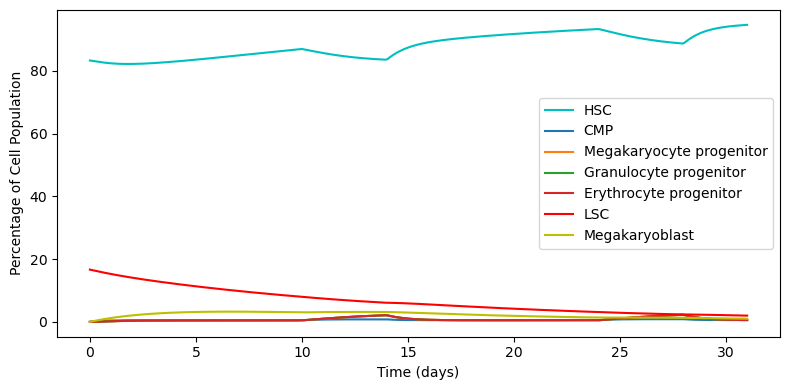

In [25]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# General Parameters
H0 = 100000 # healthy HSCs
CM0 = 0 # CMPs
K0 = 0 # megakaryocyte progenitors
G0 = 0 # granulocyte progenitors
E0 = 0 # erythrocyte progenitors
L0 = 20000 # LSCs
#LP0 = 0 # leukemic progenitors
#B0 = 0 # myeloblasts
LM0 = 0 # immature megakaryoblasts
D0 = 0 # dead cells

y0 = [H0, CM0, K0, G0, E0, L0, LM0, D0]
t_span = (0, 31)
t_eval = np.linspace(*t_span, 401)

# Rates
aH = 0.85 # renewal rate of HSCs
aCM = 0.7 # renewal rate of CMPs
aL = 0.25 # renewal rate of LSCs
aLM = 1 # renewal rate of immature megakaryoblasts
pH = 0.04 # proliferation rate of HSCs
pCM = 0.7644 # proliferation rate of CMPs
pK = 1 # proliferation rate of megakaryocyte progenitors 
pG = 1 # proliferation rate of  granulocyte progenitors 
pE = 1 # prolfieration rate of erythrocyte prongenitors
pL = 0.06 # proliferation rate of LSCs
pLM = 0.15 # proliferation rate of immature megakaryoblasts
dP = 0.3 # death rate of healthy immature progenitors
dLM = 0.1 # death rate of immature megakaryoblasts
dC = 0.99 # kill rate of chemo
EQ = 1.6 * 10**-10 # equilibrium constant
KB = 1/3 # differentiation bias from CMP to megakaryocyte progenitor
GB = 1/3 # differentiation bias from CMP to granulocyte progenitor
EB = 1/3 # differentiation bias from CMP to erythrocyte progenitor

#Treatment period. 5 days on treatment every week.  
def chemo(t, period=14, duration=10, start=0):
    t_shift = (t - start) % period
    return 1.0 if t_shift < duration else 0.

def leuk_model(t, y, aH, aCM, aL, pH, pCM, pL, dP, dC, EQ, KB, GB, EB, pLM, dLM, aLM):
    H, CM, K, G, E, L, LM, D = y
    dHdt = (2 * aH * 1/(1 + EQ * CM + EQ * LM) - 1) * pH * H - (chemo(t) * dC * pH * H)
    dCMdt = 2 * (1 - aH * 1/(1 + EQ * CM + EQ * LM)) * pH * H + (2 * aCM * KB * 1/(1 + EQ * G + EQ * LM) - 1) * pCM * CM + (2 * aCM * GB * 1/(1 + EQ * G + EQ * LM) - 1) * pCM * CM + (2 * aCM * EB * 1/(1 + EQ * G + EQ * LM) - 1) * pCM * CM - (chemo(t) * dC * pCM * CM)
    dKdt = 2 * (1 - aCM * KB * 1/(1 + EQ * CM + EQ * LM)) * pCM * CM - dP * K - (chemo(t) * dC * pK * K)
    dGdt = 2 * (1 - aCM * GB * 1/(1 + EQ * CM + EQ * LM)) * pCM * CM - dP * G - (chemo(t) * dC * pG * G)
    dEdt = 2 * (1 - aCM * EB * 1/(1 + EQ * CM + EQ * LM)) * pCM * CM - dP * E - (chemo(t) * dC * pE * E)
    dLdt = (2 * aL * 1/(1 + EQ * CM + EQ * LM) - 1) * pL * L - (chemo(t) * dC * pL * L)
    dLMdt = 2 * (1 - aL * 1/(1 + EQ * CM + EQ * LM)) * pL * L + (2 * aLM * KB * 1/(1 + EQ * G + EQ * LM) - 1) * pLM * LM - dLM * LM - (chemo(t) * dC * pLM * LM)
    dDdt = dP * K + dP * G + dP * E + dLM * LM + (chemo(t) * dC * pH * H) + (chemo(t) * dC * pCM * CM) + (chemo(t) * dC * pK * K) + (chemo(t) * dC * pG * G) + (chemo(t) * dC * pE * E) + (chemo(t) * dC * pL * L) + (chemo(t) * dC * pLM * LM)
    return [dHdt, dCMdt, dKdt, dGdt, dEdt, dLdt, dLMdt, dDdt]

sol = solve_ivp(
    fun = lambda t, y: leuk_model(t, y, aH=aH, aCM=aCM, aL=aL, pH=pH, pCM=pCM, pL=pL, dP=dP, dC=dC, EQ=EQ, KB=KB, GB=GB, EB=EB, pLM=pLM, dLM=dLM, aLM=aLM),
    t_span=t_span,
    y0=y0,
    t_eval=t_eval,
    method="RK45",
    rtol=1e-6, atol=1e-9
)

H, CM, K, G, E, L, LM, D = sol.y

total = H + CM + K + G + E + L + LM

perc_H = H / total * 100
perc_CM = CM / total * 100
perc_K = K / total * 100
perc_G = G / total * 100
perc_E = E / total * 100
perc_L = L / total * 100
perc_LM = LM / total * 100

plt.figure(figsize=(8,4))
plt.plot(sol.t, perc_H, label='HSC', color='c')
plt.plot(sol.t, perc_CM, label='CMP')
plt.plot(sol.t, perc_K, label='Megakaryocyte progenitor')
plt.plot(sol.t, perc_G, label='Granulocyte progenitor')
plt.plot(sol.t, perc_E, label='Erythrocyte progenitor')
plt.plot(sol.t, perc_L, label='LSC', color='r')
plt.plot(sol.t, perc_LM, label='Megakaryoblast', color='y')
#plt.plot(sol.t, D, label='Dead cells', color='k')
plt.xlabel('Time (days)')
plt.ylabel('Percentage of Cell Population')
plt.legend()
plt.tight_layout()
plt.show()